In [2]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:
import sys
from pathlib import Path

sys.path.append(str(Path().resolve().parent / "src"))

import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from multiprocessing import Manager
import matplotlib.pyplot as plt
import itertools
from torchmetrics import MeanSquaredError
from torchmetrics.image import PeakSignalNoiseRatio, StructuralSimilarityIndexMeasure, MultiScaleStructuralSimilarityIndexMeasure
import numpy as np
from time import time
import pandas as pd

from config import read_model_config, read_sampling_config
from data import GDPHMMSlicesDataset, SharedLRUCache, SharedCache
from model_sampler import build_sampler
from models import MambaUnet
from utils.mp import detect_device
from utils.checkpointing import load_checkpoint
from metrics import DVHScore, DoseScore, HomogeneityIndex

ModuleNotFoundError: No module named 'mamba_ssm'

In [6]:
model_name = '022-fixed'
sampling_config_name = 'ddpm-1000'
epoch = 49
data_split = 'valid'

In [7]:
def extract(v, t, x_shape):
  """
  Extract some coefficients at specified timesteps, then reshape to
  [batch_size, 1, 1, 1, 1, ...] for broadcasting purposes.
  """
  out = v.to(t.device).gather(0, t).float()
  return out.view([t.shape[0]] + [1] * (len(x_shape) - 1))

class SamplerV1(nn.Module):
  def __init__(self, model, beta_1, beta_T, train_T, sampling_T=None):
    super().__init__()

    self.model = model
    self.train_T = train_T
    self.sampling_T = sampling_T or train_T  # default: full schedule

    betas = torch.linspace(beta_1, beta_T, train_T).float()
    alphas = 1. - betas
    alphas_bar = torch.cumprod(alphas, dim=0)
    alphas_bar_prev = F.pad(alphas_bar, [1, 0], value=1)[:train_T]

    step = train_T // self.sampling_T
    self.sampling_indices = reversed(torch.arange(0, train_T, step)[:self.sampling_T].tolist())

    self.register_buffer("betas", betas)
    self.register_buffer("alphas", alphas)
    self.register_buffer("alphas_bar", alphas_bar)
    self.register_buffer("alphas_bar_prev", alphas_bar_prev)
    self.register_buffer('sqrt_recip_alphas_bar', torch.sqrt(1. / alphas_bar))
    self.register_buffer('sqrt_recipm1_alphas_bar', torch.sqrt(1. / alphas_bar - 1))

    self.register_buffer(
      'posterior_var',
      betas * (1. - alphas_bar_prev) / (1. - alphas_bar))
    self.register_buffer(
      'posterior_log_var_clipped',
      torch.log(self.posterior_var.clamp(min=1e-20)))
    self.register_buffer(
      'posterior_mean_coef1',
      torch.sqrt(alphas_bar_prev) * betas / (1. - alphas_bar))
    self.register_buffer(
      'posterior_mean_coef2',
      torch.sqrt(alphas) * (1. - alphas_bar_prev) / (1. - alphas_bar))

  def q_mean_variance(self, x_0, x_t, t):
    """
    Compute the mean and variance of the diffusion posterior
    q(x_{t-1} | x_t, x_0)
    """
    assert x_0.shape == x_t.shape
    posterior_mean = (
      extract(self.posterior_mean_coef1, t, x_t.shape) * x_0 +
      extract(self.posterior_mean_coef2, t, x_t.shape) * x_t
    )
    posterior_log_var_clipped = extract(self.posterior_log_var_clipped, t, x_t.shape)
    return posterior_mean, posterior_log_var_clipped

  def predict_xstart_from_eps(self, x_t, t, eps):
    assert x_t.shape == eps.shape
    return (
      extract(self.sqrt_recip_alphas_bar, t, x_t.shape) * x_t -
      extract(self.sqrt_recipm1_alphas_bar, t, x_t.shape) * eps
    )

  def p_mean_variance(self, x_t, condition, t):
    eps = self.model(x_t, condition, t)
    x_0 = self.predict_xstart_from_eps(x_t, t, eps)

    model_mean, model_log_var = self.q_mean_variance(x_0, x_t, t)
    return model_mean, model_log_var

  def forward(self, x_T, condition):
    x = x_T

    for t in self.sampling_indices:
      t_vec = torch.full((x.shape[0],), t, dtype=torch.long, device=x_T.device)
      mean, log_var = self.p_mean_variance(x, condition, t_vec)

      # no noise when t == 0
      if t > 0:
        noise = torch.randn_like(x)
      else:
        noise = 0
      x = mean + torch.exp(0.5 * log_var) * noise

    return x

class SamplerV2(nn.Module):
  def __init__(self, model, beta_1, beta_T, train_T, sampling_T=None):
    super().__init__()

    self.model = model
    self.train_T = train_T
    self.sampling_T = sampling_T or train_T  # default: full schedule

    betas = torch.linspace(beta_1, beta_T, train_T).float()
    alphas = 1. - betas
    alphas_bar = torch.cumprod(alphas, dim=0)

    indices = torch.linspace(self.train_T - 1, 0, self.sampling_T, dtype=torch.long)
    self.sampling_indices = indices.tolist()

    self.register_buffer("betas", betas)
    self.register_buffer("alphas", alphas)
    self.register_buffer("alphas_bar", alphas_bar)
    self.register_buffer("sqrt_betas", torch.sqrt(betas))
    self.register_buffer("sqrt_one_minus_alphas_bar", torch.sqrt(1. - alphas_bar))
    self.register_buffer("sqrt_recip_alphas", torch.sqrt(1. / alphas))

  def forward(self, x_T, condition):
    x = x_T
    for t in self.sampling_indices:
      t_vec = torch.full((x.shape[0],), t, dtype=torch.long, device=x.device)

      eps = self.model(x, condition, t_vec)

      beta_t = self.betas[t]
      sqrt_beta_t = self.sqrt_betas[t]
      sqrt_one_minus_alpha_bar_t = self.sqrt_one_minus_alphas_bar[t]
      sqrt_recip_alpha_t = self.sqrt_recip_alphas[t]

      x = sqrt_recip_alpha_t * (x - (beta_t / sqrt_one_minus_alpha_bar_t) * eps)

      if t > 0:
        noise = torch.randn_like(x)
        x += sqrt_beta_t * noise

    return x

In [ ]:
model_config = read_model_config(model_name)
sampling_config = read_sampling_config(sampling_config_name)
device = detect_device(None)

manager = Manager()
dummy_cache = SharedLRUCache(0, manager)
dataset = GDPHMMSlicesDataset(
  dataset_name=model_config['data']['dataset_name'],
  split=data_split,
  img_size=model_config['data']['img_size'],
  cache=dummy_cache,
)

dataloader = DataLoader(
  dataset,
  batch_size=16,
  shuffle=False,
)

ema_model = MambaUnet(
  img_size=model_config['data']['img_size'],
  in_struc_channels=dataset.n_structures,
).to(device)

checkpoint = load_checkpoint(model_name, epoch)
ema_model.load_state_dict(checkpoint['ema_model_state_dict'])
ema_model.eval()

# sampler = build_sampler(model_config, sampling_config, ema_model).to(device)
# sampler = SamplerV1(ema_model, model_config['beta_1'], model_config['beta_T'], model_config['T'], sampling_config['T']).to(device)
sampler = SamplerV2(ema_model, model_config['beta_1'], model_config['beta_T'], model_config['T'], sampling_config['T']).to(device)

In [ ]:
with torch.no_grad():
  # good: 64, 72, 120, 245, 256
  # bad: 0, 32, 144
  # val: 1028, 256
  structure, target, _, info = next(itertools.islice(dataloader, 0, None))
  structure = structure.to(device)
  target = target.to(device)

  x_T = torch.randn_like(target, device=device)
  start = time()
  pred = sampler(x_T, structure)
  print('Duration:', time() - start)

  pred = dataset.denormalize_target(pred)
  target = dataset.denormalize_target(target)
  print(pred.shape)
  print(info)

Duration: 123.42516732215881
torch.Size([16, 1, 176, 160])
{'file_path': ['/work/data/gdphmm-hn-vmat/valid/HN-HGJ-069+S2A4Ac+MOS_22563.npz', '/work/data/gdphmm-hn-vmat/valid/HN-HGJ-069+S2A4Ac+MOS_22563.npz', '/work/data/gdphmm-hn-vmat/valid/HN-HGJ-069+S2A4Ac+MOS_22563.npz', '/work/data/gdphmm-hn-vmat/valid/HN-HGJ-069+S2A4Ac+MOS_22563.npz', '/work/data/gdphmm-hn-vmat/valid/HN-HGJ-069+S2A4Ac+MOS_22563.npz', '/work/data/gdphmm-hn-vmat/valid/HN-HGJ-069+S2A4Ac+MOS_22563.npz', '/work/data/gdphmm-hn-vmat/valid/HN-HGJ-069+S2A4Ac+MOS_22563.npz', '/work/data/gdphmm-hn-vmat/valid/HN-HGJ-069+S2A4Ac+MOS_22563.npz', '/work/data/gdphmm-hn-vmat/valid/HN-HGJ-069+S2A4Ac+MOS_22563.npz', '/work/data/gdphmm-hn-vmat/valid/HN-HGJ-069+S2A4Ac+MOS_22563.npz', '/work/data/gdphmm-hn-vmat/valid/HN-HGJ-069+S2A4Ac+MOS_22563.npz', '/work/data/gdphmm-hn-vmat/valid/HN-HGJ-069+S2A4Ac+MOS_22563.npz', '/work/data/gdphmm-hn-vmat/valid/HN-HGJ-069+S2A4Ac+MOS_22563.npz', '/work/data/gdphmm-hn-vmat/valid/HN-HGJ-069+S2A4Ac+MOS_

Batch Size vs. Seconds
- 1: 50s (50s)
- 64: 340s (5.3s)
- 128: 706s (5.5s)

In [41]:
pred.flatten().min(), pred.flatten().max()

(tensor(-1.7940, device='cuda:0'), tensor(1.8245, device='cuda:0'))

In [42]:
target.flatten().min(), target.flatten().max()

(tensor(0., device='cuda:0'), tensor(1.6797, device='cuda:0'))

In [43]:
pred = torch.clamp(pred, dataset.dose_range[0], dataset.dose_range[1])

HN-HGJ-069+S2A4Ac+MOS_22563.npz tensor(15)


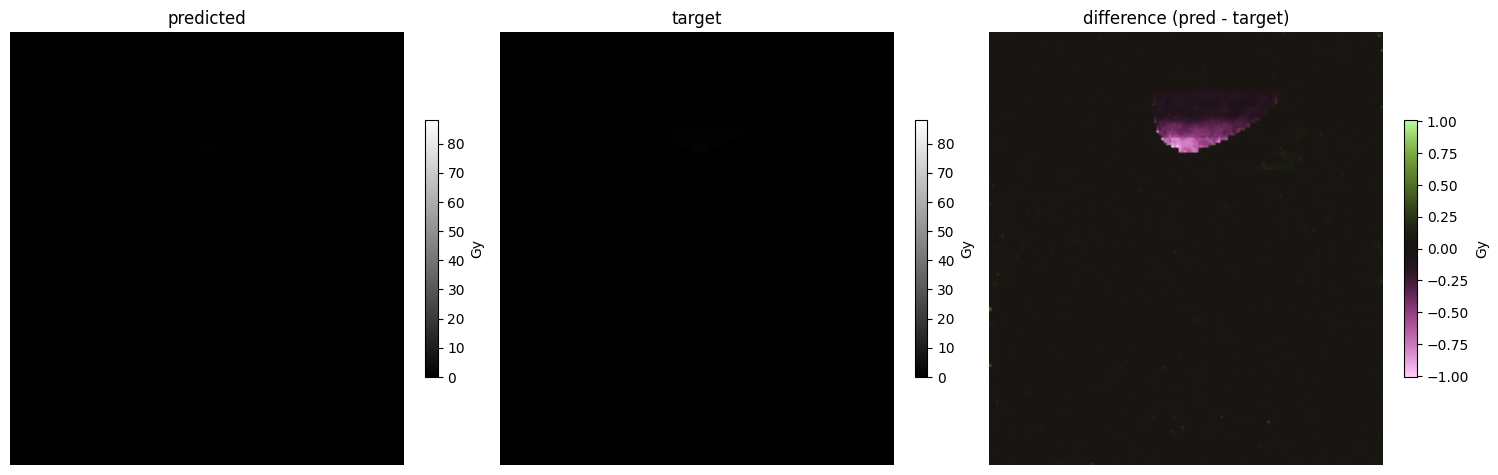

In [56]:
i = 15

fig, axs = plt.subplots(1, 3, figsize=(15, 5))
shw0 = axs[0].imshow(pred[i, 0].cpu().numpy(), cmap='gray', vmin=dataset.dose_range[0], vmax=dataset.dose_range[1])
shw1 = axs[1].imshow(target[i, 0].cpu().numpy(), cmap='gray', vmin=dataset.dose_range[0], vmax=dataset.dose_range[1])

diff = pred[i, 0].cpu().numpy() - target[i, 0].cpu().numpy()
max_diff = np.max([np.abs(diff.min()), np.abs(diff.max())])
shw2 = axs[2].imshow(diff, cmap='vanimo', vmin=-max_diff, vmax=max_diff)

axs[0].set_title('predicted')
axs[1].set_title('target')
axs[2].set_title('difference (pred - target)')

axs[0].set_axis_off()
axs[1].set_axis_off()
axs[2].set_axis_off()

fig.colorbar(shw0, ax=axs[0], fraction=0.03, label='Gy')
fig.colorbar(shw1, ax=axs[1], fraction=0.03, label='Gy')
fig.colorbar(shw2, ax=axs[2], fraction=0.03, label='Gy')

fig.tight_layout()

print(info['file_name'][i], info['index'][i])

In [26]:
dose_range = dataset.dose_range[1] - dataset.dose_range[0]
metrics = {
  'mse': MeanSquaredError(sync_on_compute=False),
  'rmse': MeanSquaredError(squared=False, sync_on_compute=False),
  'psnr': PeakSignalNoiseRatio(data_range=dose_range, sync_on_compute=False),
  'ssim': StructuralSimilarityIndexMeasure(data_range=dose_range, sync_on_compute=False),
  'ms_ssim': MultiScaleStructuralSimilarityIndexMeasure(
    data_range=dataloader.dataset.dose_range,
    betas=(0.0448, 0.2856, 0.3001, 0.2363), # only 4 values since image size is 160x176
    sync_on_compute=False,
  ),
  'dvh': DVHScore(sync_on_compute=False),
  'dose_score': DoseScore(sync_on_compute=False),
  'homogeneity_index': HomogeneityIndex(sync_on_compute=False)
}

metrics = {k: v.to(device) for k, v in metrics.items()}

In [50]:
scores = {}
for metric_name, metric in metrics.items():
  metric.reset()
  m_kwargs = {'mask': structure[:, 1]} if metric_name == 'homogeneity_index' else {}
  metric.update(pred, target, **m_kwargs)
  scores[metric_name] = metric.compute().item()

print(scores)

{'mse': 0.0008810121798887849, 'rmse': 0.029681850224733353, 'psnr': 69.43983459472656, 'ssim': 0.9995362758636475, 'ms_ssim': 0.9999250173568726, 'dvh': 0.03635267913341522, 'dose_score': 0.009327281266450882, 'homogeneity_index': nan}


In [40]:
D2 = torch.quantile(pred[0], 1 - 0.02)
D98 = torch.quantile(pred[0], 1 - 0.98)
D50 = torch.quantile(pred[0], 1 - 0.5)

(D2 - D98) / D50

tensor(65552.3203, device='cuda:0')

In [75]:
structure[:, 1].max()

tensor(0., device='cuda:0')

In [ ]:
overall_metrics = pd.read_csv(Path('..') / 'checkpoints' / model_name / f'epoch-{epoch}' / '_overall_metrics.csv')
sample_metrics = pd.read_csv(Path('..') / 'checkpoints' / model_name / f'epoch-{epoch}' / '_sample_metrics.csv')

In [10]:
overall_metrics

,slice_index,duration,mse,rmse,psnr,ssim,ms_ssim,dvh,dose_score,homogeneity_index
0,100.325181,3.690095,35.138737,5.05032,27.87268,0.455401,0.712028,3.004406,2.566005,0.312206


In [11]:
sample_metrics.mean(numeric_only=True)

slice_index          100.325181
duration               3.690095
mse                   35.138737
rmse                   5.050320
psnr                  27.872680
ssim                   0.455401
ms_ssim                0.712028
dvh                    3.004406
dose_score             2.566005
homogeneity_index      0.312206
dtype: float64

In [12]:
sample_metrics.groupby(['file_name', 'slice_index']).size().value_counts()

1    1799
Name: count, dtype: int64

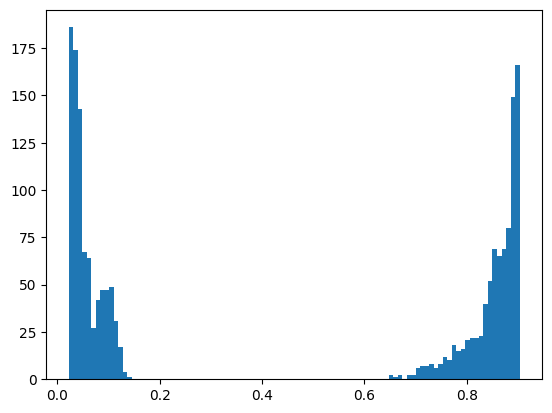

In [15]:
plt.hist(sample_metrics['ssim'], bins=100)
plt.show()

In [16]:
sample_metrics[(sample_metrics['ssim'] < 0.1) & (sample_metrics['file_name'] == 'HN-HGJ-069+S2A4Ac+MOS_22563.npz')]

,file_name,slice_index,duration,mse,rmse,psnr,ssim,ms_ssim,dvh,dose_score,homogeneity_index
900,HN-HGJ-069+S2A4Ac+MOS_22563.npz,1,3.670333,34.963402,5.912986,23.453516,0.024745,0.386323,6.559017,3.330742,NaN
901,HN-HGJ-069+S2A4Ac+MOS_22563.npz,3,3.670333,33.392666,5.778639,23.653143,0.027466,0.399694,6.510440,3.215751,NaN
902,HN-HGJ-069+S2A4Ac+MOS_22563.npz,5,3.670333,35.981441,5.998453,23.328869,0.024339,0.383894,6.634843,3.370751,NaN
903,HN-HGJ-069+S2A4Ac+MOS_22563.npz,7,3.670333,35.320049,5.943068,23.409441,0.025766,0.389308,6.711566,3.313385,NaN
904,HN-HGJ-069+S2A4Ac+MOS_22563.npz,9,3.670333,33.615807,5.797914,23.624216,0.027233,0.404652,6.395967,3.246176,NaN
...,...,...,...,...,...,...,...,...,...,...,...
990,HN-HGJ-069+S2A4Ac+MOS_22563.npz,181,3.670333,34.805946,5.899656,23.473118,0.026735,0.394704,6.502188,3.298107,NaN
991,HN-HGJ-069+S2A4Ac+MOS_22563.npz,183,3.670333,35.554394,5.962750,23.380718,0.024589,0.390512,6.389240,3.375240,NaN
992,HN-HGJ-069+S2A4Ac+MOS_22563.npz,185,3.670333,32.449558,5.696451,23.777565,0.028577,0.404020,6.355835,3.179553,NaN
993,HN-HGJ-069+S2A4Ac+MOS_22563.npz,187,3.670333,34.819828,5.900833,23.471386,0.025419,0.389863,6.555017,3.300752,NaN


In [17]:
sample_metrics[sample_metrics['ssim'] < 0.1]['file_name'].value_counts()

file_name
HNC_078+A4Ac+MOS_3752.npz           95
HNSCC-01-0127+A4Ac+MOS_3750.npz     95
HNSCC-01-0196+A4Ac+MOS_59748.npz    93
HNSCC-01-0009+A4Ac+MOS_56603.npz    93
HN-HMR-021+S2A4Ac+MOS_22335.npz     90
HNC_044+A4Ac+MOS_5466.npz           88
0522c0883+A4Ac+MOS_188.npz          79
HN-HGJ-069+S2A4Ac+MOS_22563.npz     78
HNC_178+A4Ac+MOS_223.npz            77
Name: count, dtype: int64

In [54]:
sample_metrics['file_name'].value_counts()

file_name
HNC_078+A4Ac+MOS_3752.npz           240
HNC_044+A4Ac+MOS_5466.npz           226
HNSCC-01-0196+A4Ac+MOS_59748.npz    200
0522c0883+A4Ac+MOS_188.npz          196
HN-HGJ-069+S2A4Ac+MOS_22563.npz     192
HNSCC-01-0009+A4Ac+MOS_56603.npz    190
HNSCC-01-0127+A4Ac+MOS_3750.npz     190
HN-HMR-021+S2A4Ac+MOS_22335.npz     186
HNC_178+A4Ac+MOS_223.npz            180
Name: count, dtype: int64

In [ ]:
collection = []
for s, t, i in dataset:
  if s[1].sum().item() > 0:
    collection.append(i)

print(len(collection))

In [17]:
dataset[0][0][1].sum()

tensor(0.)

In [20]:
dataset

In [39]:
slc_pred = np.load(Path('..') / 'checkpoints' / model_name / f'epoch-{epoch}' / 'HN-HGJ-069+S2A4Ac+MOS_22563-82.npy')
slc_pred.shape

(1, 176, 160)

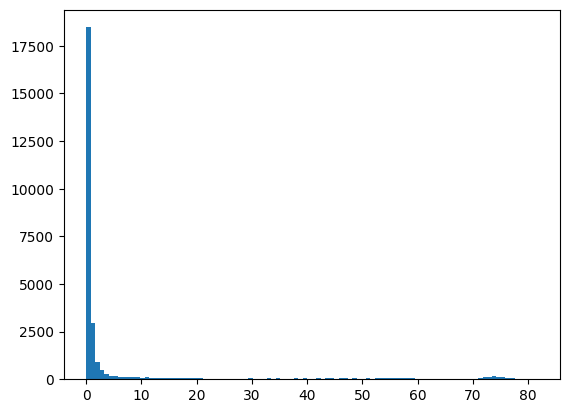

In [40]:
plt.hist(slc_pred.flatten(), bins=100)
plt.show()

In [ ]:
idx = next((i for i, x in enumerate(dataset.index_map) if x[0].name == "HN-HGJ-069+S2A4Ac+MOS_22563.npz" and x[1] == 82))
slc_structure, slc_target, _, info = dataset[idx]
slc_structure = slc_structure.to(device).unsqueeze(dim=0)
slc_target = slc_target.to(device).unsqueeze(dim=0)
print(info)
print(slc_structure.shape, slc_target.shape)

{'file_path': '/work/data/gdphmm-hn-vmat/valid/HN-HGJ-069+S2A4Ac+MOS_22563.npz', 'file_name': 'HN-HGJ-069+S2A4Ac+MOS_22563.npz', 'volume': 'HN-HGJ-069+S2A4Ac+MOS_22563', 'index': 82}
torch.Size([1, 35, 176, 160]) torch.Size([1, 1, 176, 160])


In [43]:
slc_pred = torch.tensor(slc_pred).unsqueeze(dim=0).to(device)

scores = {}
for metric_name, metric in metrics.items():
  metric.reset()
  m_kwargs = {'mask': slc_structure[:, 1]} if metric_name == 'homogeneity_index' else {}
  metric.update(slc_pred, slc_target, **m_kwargs)
  scores[metric_name] = metric.compute().item()

print(scores)

{'mse': 359.66949462890625, 'rmse': 18.964954376220703, 'psnr': 13.33061695098877, 'ssim': 0.6488714814186096, 'ms_ssim': 0.624107837677002, 'dvh': 24.840595245361328, 'dose_score': 7.063812732696533, 'homogeneity_index': 0.11397486180067062}


In [67]:
c = SharedLRUCache(10, manager)

In [68]:
c.put('test', np.zeros(10))

In [72]:
c.data['test']

('psm_edf407eb', (10,), dtype('float64'), 80)

In [4]:
manager = Manager()
cache = SharedLRUCache(10, manager)
dataset = GDPHMMSlicesDataset('gdphmm-hn', 'train', [176, 160], cache)

In [6]:
_ = dataset[0]

(128, 108, 177) (128, 108, 177) (128, 108, 177) (33, 128, 108, 177) (128, 108, 177)
